This is a CNN model with binary classification of Covid vs Normal (Healthy)

2 datasets are being used.<br> 2 classes were taken from dataset1 - Covid and Normal (Healthy)
<br>1 class was taken from dataset 2 -Covid positive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#paths for 2 datasets. Covid

pathC_d1 = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/COVID-19 Radiography Database/COVID"
pathN_d1 = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/COVID-19 Radiography Database/NORMAL"

pathC_d2 = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/COVIDGR 1.0/COVIDGR_1.0/P"

manifest1_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/manifests/dataset1_clean_manifest.csv"
manifest2_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/manifests/dataset2_clean_manifest.csv"

In [ ]:
import os

datasets_root = "/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets"

for root, dirs, files in os.walk(datasets_root):
    if os.path.basename(root) == "P":
        print(root)

/content/drive/MyDrive/PSUPRProject_2026Sem2/datasets/COVIDGR 1.0/COVIDGR_1.0/P


In [ ]:
import os

# Function to count image files
def count_images(folder):
    extensions = (".png", ".jpg", ".jpeg", ".bmp")

    return sum(
        1 for f in os.listdir(folder)
        if f.lower().endswith(extensions)
    )


print("Dataset 1 COVID :", count_images(pathC_d1))
print("Dataset 1 Normal:", count_images(pathN_d1))
print("Dataset 2 COVID :", count_images(pathC_d2))

Dataset 1 COVID : 1200
Dataset 1 Normal: 1341
Dataset 2 COVID : 426


In [ ]:
import pandas as pd
import os

manifest1 = pd.read_csv(manifest1_path)   #covid radiograpghy db
manifest2 = pd.read_csv(manifest2_path)   #covidgr 1.0

In [ ]:
# -------------------------
# Dataset 1 - COVID
# -------------------------
d1_covid = manifest1[
    manifest1["label"] == "COVID"
].copy()

d1_covid["filepath"] = d1_covid["filename"].apply(
    lambda x: os.path.join(pathC_d1, x)
)

d1_covid["class"] = "COVID"
d1_covid["source"] = "Dataset1"


# -------------------------
# Dataset 1 - Normal
# -------------------------
d1_normal = manifest1[
    manifest1["label"] == "Healthy"
].copy()

d1_normal["filepath"] = d1_normal["filename"].apply(
    lambda x: os.path.join(pathN_d1, x)
)

d1_normal["class"] = "Normal"
d1_normal["source"] = "Dataset1"


# -------------------------
# Dataset 2 - COVID
# -------------------------
d2_covid = manifest2[
    manifest2["original_label"] == "COVID"
].copy()

d2_covid["filepath"] = d2_covid["filename"].apply(
    lambda x: os.path.join(pathC_d2, x)
)

d2_covid["class"] = "COVID"
d2_covid["source"] = "Dataset2"

In [ ]:
modelB_df = pd.concat(
    [
        d1_covid[["filename", "filepath", "class", "source"]],
        d1_normal[["filename", "filepath", "class", "source"]],
        d2_covid[["filename", "filepath", "class", "source"]]
    ],
    ignore_index=True
)

print("Total images:", len(modelB_df))

print("\nClass counts:")
print(modelB_df["class"].value_counts())

print("\nSource + class counts:")
print(modelB_df.groupby(["source", "class"]).size())

display(modelB_df.head())

Total images: 2966

Class counts:
class
COVID     1626
Normal    1340
Name: count, dtype: int64

Source + class counts:
source    class 
Dataset1  COVID     1200
          Normal    1340
Dataset2  COVID      426
dtype: int64


,filename,filepath,class,source
0,COVID (365).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1
1,COVID (529).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1
2,COVID (412).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1
3,COVID (707).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1
4,COVID (650).png,/content/drive/MyDrive/PSUPRProject_2026Sem2/d...,COVID,Dataset1


In [ ]:
modelB_df["exists"] = modelB_df["filepath"].apply(os.path.exists)

print("Files found :", modelB_df["exists"].sum())
print("Files missing:", (~modelB_df["exists"]).sum())

if not modelB_df["exists"].all():
    display(modelB_df[~modelB_df["exists"]])

Files found : 2966
Files missing: 0


In [ ]:
modelB_df = modelB_df.drop(columns=["exists"], errors="ignore")

TRAIN TEST SPLIT

MODEL B: covid 1628, non covid 426
covid from d1 and d2. non covid from d2

In [ ]:
from sklearn.model_selection import train_test_split

#70% train 30% temp
#this 30% will become 15% 15% for validation and testing
train_df, temp_df = train_test_split(
    modelB_df,
    test_size = 0.30,
    random_state=42,
    stratify=modelB_df["class"]
)


#30% temp
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=32,
    stratify=temp_df["class"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Train: 2076
Validation: 445
Test: 445


In [ ]:
#check if the class distribution stays approximately the same

print("\nTRAIN")
print(train_df["class"].value_counts())
print(train_df["class"].value_counts(normalize=True).round(3))

print("\nVALIDATION")
print(val_df["class"].value_counts())
print(val_df["class"].value_counts(normalize=True).round(3))

print("\nTEST")
print(test_df["class"].value_counts())
print(test_df["class"].value_counts(normalize=True).round(3))


TRAIN
class
COVID     1138
Normal     938
Name: count, dtype: int64
class
COVID     0.548
Normal    0.452
Name: proportion, dtype: float64

VALIDATION
class
COVID     244
Normal    201
Name: count, dtype: int64
class
COVID     0.548
Normal    0.452
Name: proportion, dtype: float64

TEST
class
COVID     244
Normal    201
Name: count, dtype: int64
class
COVID     0.548
Normal    0.452
Name: proportion, dtype: float64


224 X 224 Pixel Normalization

In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [ ]:
#Function to read an image from its filepath, decodes it, resizes it and normalizes it

def load_and_preprocess_image(filepath,label):

  #read image
  image = tf.io.read_file(filepath)

  #decode image and force 3 channels
  image = tf.io.decode_image(
      image,
      channels=3,
      expand_animations=False #this will force 3D tensor (height, width, channels)
  )

  #resize to 224 x 224
  image = tf.image.resize(image, IMG_SIZE)


  #convert pixel values from -0255 to 0-1
  image = tf.cast(image, tf.float32) / 255.0

  return image, label

In [ ]:
#label mapping

label_map = {
    "Normal" : 0,
    "COVID" : 1
}

train_df["label_num"] = train_df["class"].map(label_map)
val_df["label_num"]   = val_df["class"].map(label_map)
test_df["label_num"]  = test_df["class"].map(label_map)

print(train_df[["filename", "class", "label_num"]].head())

              filename   class  label_num
353    COVID (348).png   COVID          1
465   COVID (1006).png   COVID          1
164    COVID (865).png   COVID          1
255    COVID (693).png   COVID          1
1956  NORMAL (173).png  Normal          0


In [ ]:
#CONVERT the dataframes into tensorflow datasets

def create_dataset(df, training=False):

  dataset = tf.data.Dataset.from_tensor_slices(
      (
          df["filepath"].values,
          df["label_num"].values
      )
  )

#shuffle training data only
  if training:
    dataset = dataset.shuffle(
        buffer_size=len(df),
        seed=42
    )

#load and preprocess images
  dataset = dataset.map(
      load_and_preprocess_image,
      num_parallel_calls=tf.data.AUTOTUNE
  )


#group images into batches
  dataset = dataset.batch(BATCH_SIZE)

#Prepare next batch while gpu is working
  dataset = dataset.prefetch(tf.data.AUTOTUNE)

  return dataset


In [ ]:
train_ds = create_dataset(train_df, training=True)
val_ds   = create_dataset(val_df)
test_ds  = create_dataset(test_df)

In [ ]:
#verify what CNN will actually receive
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("\nPixel minimum:", tf.reduce_min(images).numpy())
    print("Pixel maximum:", tf.reduce_max(images).numpy())

    print("\nFirst 10 labels:")
    print(labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)

Pixel minimum: 0.0
Pixel maximum: 1.0

First 10 labels:
[0 0 1 1 1 0 1 0 1 1]


START TRAINING CNN FOR NORMAL = 0 , COVID = 1. BINARY CLASSIFICATION

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

model_B = keras.Sequential([
    #input
    layers.Input(shape=(224, 224, 3)),

    #concolution block 1
    layers.Conv2D(
        filters=32,
        kernel_size=(3,3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2,2)),

    #concolution block 2
    layers.Conv2D(
        filters=64,
        kernel_size=(3,3),
        activation="relu",
        padding="same"
    ),
       layers.MaxPooling2D(pool_size=(2,2)),

    #convolution block3
    layers.Conv2D(
        filters=128,
        kernel_size=(3,3),
        activation="relu",
        padding="same"
    ),
       layers.MaxPooling2D(pool_size=(2,2)),

    #convert featur maps to a vector
    layers.Flatten(),

    #classification
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    #binary output
    layers.Dense(1, activation="sigmoid")
])

model_B.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,561 (49.36 MB)

 Trainable params: 12,938,561 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

896 parameters come from
(3 x 3 x 3 + 1 ) x 32 = 896

In [ ]:
#compile
model_B.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Adam → optimizer that updates the ~12.9 million trainable parameters.
learning_rate=0.001 → standard starting point for Adam.
binary_crossentropy → appropriate because we have binary classification: Normal=0, COVID=1.
accuracy → tracks classification accuracy while training.

In [ ]:
#checkpoint saving and callback since colab can get stuck
checkpoint_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_25sep.keras"

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

In [ ]:
earlystop_cb = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,                     #early stopping if the validation loss doesnt beat the best value for 5 consecutive epochs
    mode="min",
    restore_best_weights=True,
    verbose=1
)

In [ ]:
history_B = model_B.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        checkpoint_cb,
        earlystop_cb
    ]
)

Epoch 1/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.8142 - loss: 0.6286
Epoch 1: val_loss improved from None to 0.07500, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_25sep.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_25sep.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 34s 474ms/step - accuracy: 0.9162 - loss: 0.2642 - val_accuracy: 0.9730 - val_loss: 0.0750
Epoch 2/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - accuracy: 0.9824 - loss: 0.0579
Epoch 2: val_loss improved from 0.07500 to 0.05852, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_25sep.keras

Epoch 2: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_25sep.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 43s 545ms/step - accuracy: 0.9822 - loss: 0.0605 - val_accuracy: 0.9865 - val_loss: 0.0585
Epoch 3/20
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.9894 - loss: 0.0325
Epoch 3: val_lo

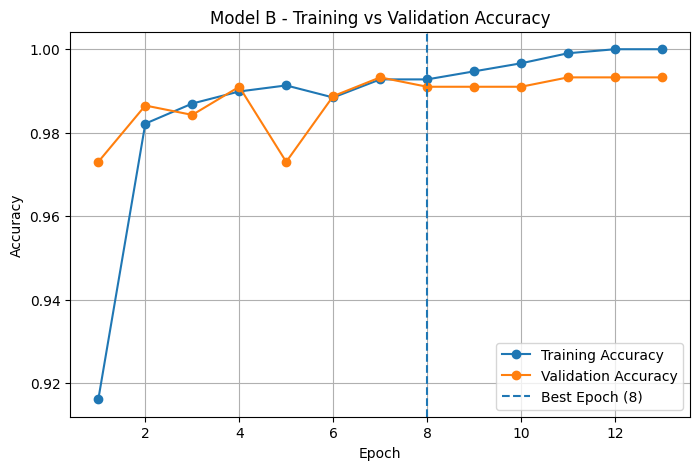

In [ ]:
import matplotlib.pyplot as plt

# Extract training history
train_acc = history_B.history["accuracy"]
val_acc   = history_B.history["val_accuracy"]

train_loss = history_B.history["loss"]
val_loss   = history_B.history["val_loss"]

epochs = range(1, len(train_acc) + 1)

# Accuracy plot
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_acc, marker="o", label="Training Accuracy")
plt.plot(epochs, val_acc, marker="o", label="Validation Accuracy")

plt.axvline(
    x=8,
    linestyle="--",
    label="Best Epoch (8)"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model B - Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

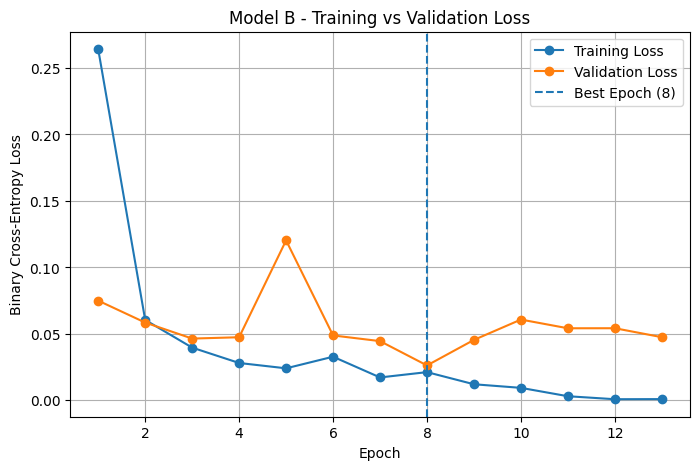

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_loss, marker="o", label="Training Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")

plt.axvline(
    x=8,
    linestyle="--",
    label="Best Epoch (8)"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Model B - Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

from the loss graph, we can see after epoch 8, training loss decreases but validation loss increases. it can signal overfitting.

The accuracy graph is less obvious because validation accuracy stays around 99% even though the loss worsens. This is because accuracy only asks right or wrong while binary cross-entropy also penalizes how confidently wrong the model is.

Suppose the actual Xray is covid. y = 1

case 1 -  correct and confident
<br>model predicts p = 0.99
<br>since 0.99 > 0.5, prediction = covid. so accuracy says correct.
<br><br>For a COVID sample (y=1), BCE simplifies to:
Loss=−log(p)
Therefore:

$$ -\log(0.99)=0.010 $$

Very small loss → good.

<br>Case 2 — Wrong, but not very confident
<br>Model predicts: p=0.49
<br>Since 0.49 < 0.5, prediction = Normal.
<br>Accuracy says:Wrong
<br>Loss:
−log(0.49)=0.713

<br>Case 3 — Wrong AND extremely confident
<br>Now suppose the model predicts:
$$ p=0.01 $$
It's basically saying:
"I'm 99% sure this is Normal."
But the patient is actually COVID.
<br>Accuracy still just says:Wrong
But BCE says:
−log(0.01)=4.605
That's a huge loss.

Accuracy only sees:
0.49 → WRONG
0.01 → WRONG

BCE sees:
0.49 → wrong, but close to decision boundary → loss 0.713
0.01 → extremely confident and wrong       → loss 4.605

In [ ]:
#use the test set
test_loss, test_accuracy = model_B.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

14/14 ━━━━━━━━━━━━━━━━━━━━ 123s 9s/step - accuracy: 0.9933 - loss: 0.0233
Test Loss: 0.023260600864887238
Test Accuracy: 0.9932584166526794


the numerical values look good after testing on the test set

PREDICTIONS, CONFUSION MATRIX, PRECISION, RECALL, F1, ROC-AUC

In [ ]:
#each value is the model's predicted probability of covid
y_prob = model_B.predict(test_ds)

print(y_prob[:10])
print("Shape:", y_prob.shape)

14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 431ms/step
[[9.9999785e-01]
 [9.9989486e-01]
 [9.9996471e-01]
 [9.4758958e-01]
 [9.9999011e-01]
 [9.9996495e-01]
 [6.8968587e-04]
 [9.9958152e-01]
 [8.2416125e-07]
 [1.4613428e-06]]
Shape: (445, 1)


(445,1) meaning
445 = number of test images
1 = one sigmoid probability per image

this is the model's first 10 prob predictions
8.2416125×10−7=0.000000824
meaning the value is so close to 0. the model is very confident about Normal

In [ ]:
#convert probabilities into predictions
y_pred = (y_prob.flatten() >= 0.5).astype(int)

# Actual labels
y_true = test_df["label_num"].values.astype(int)

print("Actual:   ", y_true[:20])
print("Predicted:", y_pred[:20])

Actual:    [1 1 1 1 1 1 0 1 0 0 0 1 0 0 0 0 1 0 1 1]
Predicted: [1 1 1 1 1 1 0 1 0 0 0 1 0 0 0 0 1 0 1 1]


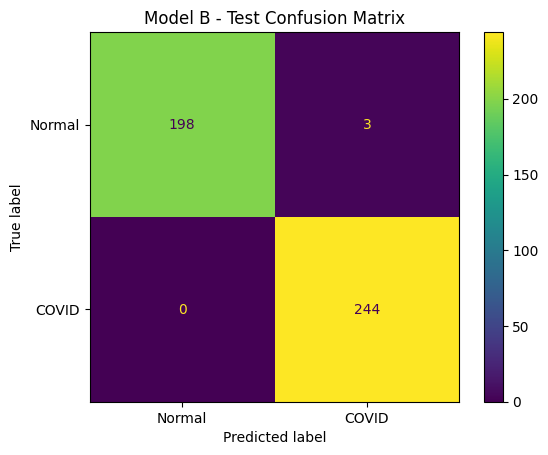

[[198   3]
 [  0 244]]


In [ ]:
#confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "COVID"]
)

disp.plot()
plt.title("Model B - Test Confusion Matrix")
plt.show()

print(cm)

True Negative = 198
False Positive = 3
False negative = 0
True positive = 244


In [ ]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Normal", "COVID"],
        digits=4
    )
)

auc = roc_auc_score(y_true, y_prob.flatten())

print("ROC-AUC:", round(auc, 4))

              precision    recall  f1-score   support

      Normal     1.0000    0.9851    0.9925       201
       COVID     0.9879    1.0000    0.9939       244

    accuracy                         0.9933       445
   macro avg     0.9939    0.9925    0.9932       445
weighted avg     0.9933    0.9933    0.9933       445

ROC-AUC: 0.9995


F1 = combines precision and recall
F1 = 2(precision x recall/precision + recall) = 0.9939


ROC = Receiver Operating Characteristic curve. Instead of evaluating your model only at the 0.5 threshold, ROC asks:
What happens to COVID detection if I move the classification threshold from almost 0 all the way to 1?

True Positive Rate (Recall)=TP/(TP+FN)

False Positive Rate = FP/(FP+TN)

Threshold = 0.9  → harder to call something COVID
Threshold = 0.5  → our current classification
Threshold = 0.2  → easier to call something COVID
Usually there's a trade-off: lowering the threshold catches more COVID cases but may incorrectly flag more Normal cases.
<br>AUC = Area Under the ROC Curve.
It summarizes the entire ROC curve into one number:
<br>AUC = 0.50 → no discrimination / random-like ranking
<br>AUC = 0.80 → substantial separation
<br>AUC = 1.00 → perfect separation

My AUC = 0.9995
If I randomly select one COVID X-ray and one Normal X-ray from this test set, there is about a 99.95% chance that the model assigns the COVID image a higher COVID score than the Normal image.

So accuracy tells us performance at our chosen 0.5 threshold; ROC-AUC tells us how well the prediction scores separate the two classes across thresholds.

save training history from the reconstructed model manually cos the colab runtime restarted.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

# Training history manually reconstructed from the original Colab output.
# Uses the FINAL metrics reported after each completed epoch.

history_df = pd.DataFrame({
    "epoch": range(1, 14),

    "accuracy": [
        0.9162,
        0.9822,
        0.9870,
        0.9899,
        0.9913,
        0.9884,
        0.9928,
        0.9928,
        0.9947,
        0.9966,
        0.9990,
        1.0000,
        1.0000
    ],

    "loss": [
        0.2642,
        0.0605,
        0.0397,
        0.0281,
        0.0241,
        0.0328,
        0.0172,
        0.0212,
        0.0121,
        0.0094,
        0.0031,
        8.4038e-04,
        9.3062e-04
    ],

    "val_accuracy": [
        0.9730,
        0.9865,
        0.9843,
        0.9910,
        0.9730,
        0.9888,
        0.9933,
        0.9910,
        0.9910,
        0.9910,
        0.9933,
        0.9933,
        0.9933
    ],

    "val_loss": [
        0.0750,
        0.0585,
        0.0465,
        0.0475,
        0.1203,
        0.0488,
        0.0446,
        0.0263,
        0.0455,
        0.0608,
        0.0542,
        0.0542,
        0.0475
    ]
})

display(history_df)

,epoch,accuracy,loss,val_accuracy,val_loss
0,1,0.9162,0.264200,0.9730,0.0750
1,2,0.9822,0.060500,0.9865,0.0585
2,3,0.9870,0.039700,0.9843,0.0465
3,4,0.9899,0.028100,0.9910,0.0475
4,5,0.9913,0.024100,0.9730,0.1203
5,6,0.9884,0.032800,0.9888,0.0488
6,7,0.9928,0.017200,0.9933,0.0446
7,8,0.9928,0.021200,0.9910,0.0263
8,9,0.9947,0.012100,0.9910,0.0455
9,10,0.9966,0.009400,0.9910,0.0608


In [4]:
history_path = "/content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_training_history_25sep.csv"

history_df.to_csv(history_path, index=False)

print("Saved:", history_path)

Saved: /content/drive/MyDrive/PSUPRProject_2026Sem2/models/model_B_training_history_25sep.csv


Plan to improve this model

1. Potential dataset confounding (first dataset is known as pediatric; Dataset2 is COVID-only)<br>
- try GRAD-CAM : source-prediction test<br>
- cross-dataset testing : train only on dataset1 then test on dataset2 with both classes to fish out more false negatives
<br>
<br>
2. Potential data leakage (forgot to check the duplicate/near duplicate images and handle them in this new notebook)<br>
- hash deduplication
<br>
<br>
3. Need more robust preprocessing<br>
- augmentation<br>
- use resize with pad to preserve aspect ratio
<br>
<br>
4. Improve reproducibility<br>
- Weight initialization and dropout weren't seeded (Only the data shuffle was). Need to seed everything at the same rate
<br>
<br>
5. Model too large for the data<br>
- replace flatten with globalaveragepooling2D()<br>
- add batchnormalization after the conv layers<br>
- try transfer learning (already in plan)
<br>
<br>
6. Evaluation
- Look at the errors: view the 3 false positives to reveal more<br>
- plot ROC curve rather than only reporting AUC<br>
- report confidence intervals. Bootsrap CI on accuracy, recall and AUC